<a href="https://colab.research.google.com/github/nuralfiyanti/ML_Ganjil2026/blob/main/JS11ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Nur Alfiyanti

NIM : 244107020055

Kelas : TI-3E

JS09 - Klasifikasi 2

## **Praktikum 1**

Klasifikasi SVM dengan Data Dummy Linier

**Pengantar**

Pada praktikum ini membutuhkan dataset untuk diolah datanya menjadi sebuah analisis dari luaran metode SVM yang dijalankan. Ikuti petunjuk dari dosen pengampu mengenai data apa saja yang boleh dipakai serta karakteristik yang sesuai untuk kegiatan praktikum kali ini. Data yang ditampilkan pada jobsheet hanya sebuah contoh, mahasiswa harus mencari data sendiri dan memastikan data yang diperoleh tersebut sesuai dengan kasus yang dapat diselesaikan dengan SVM.



**Langkah 1 - Import Library**



In [ ]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

**Langkah 2 - Membuat Data Dummy**

Pada praktikum ini, model yang digunakan adalah sebuah model yang sederhana berupa generative model untuk menentukan label pada poin baru. Kasus pada data dummy ini memperlihatkan dua kelas yang telah terpisah.

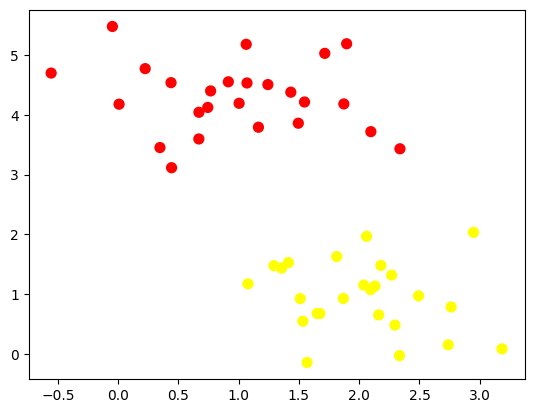

In [ ]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

**Langkah 3 - Buat Ilustrasi Garis Pemisah**

Untuk membuat sebuah model klasifikasi, garis pemisah data dari dua buah himpunan yang terbentuk diperlukan. Namun, kondisi ini masih menyisakan kasus dimana garis pemisah yang dibutuhkan lebih dari satu garis.

Banyaknya garis pemisah menunjukkan bahwa muncul beberapa kemungkinan suatu data baru masuk dalam kategori tertentu. Sebuah data baru 'x' dimunculkan pada posisi yang berbeda dengan data pada dua himpunan lain sehingga data baru ini tidak masuk ke dalam kategori dua himpunan sebelumnya.

**Langkah 4 - Ilustrasi Margin**

Margin dalam suatu garis juga dapat digunakan untuk memperjelas posisi sebuah data terhadap label.




(-1.0, 3.5)

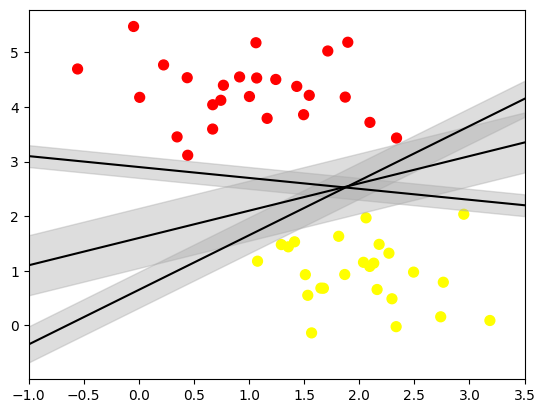

In [ ]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

Margin yang digunakan pada SVM berfungsi untuk menunjukkan model yang paling optimal. Kriteria optimal ini diperoleh dari penentuan garis mana yang mampu memaksimalkan margin yang ada.



**Langkah 5 - Fitting Model**

Selanjutnya, kita akan melakukan pelatihan terhadap model SVM. Model kali ini akan menggunakan fungsi (kernel) dengan jenis linier.




In [ ]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

Selanjutnya buat fungsi untuk membantu visualisasi hasil fit model.




In [ ]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Lakukan plotting dengan fungsi yang telah dibuat.




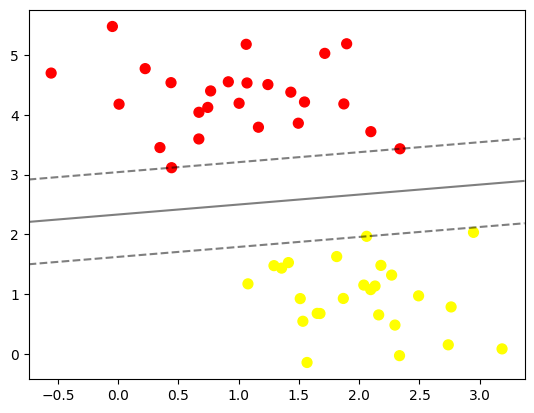

In [ ]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

Beberapa titik data yang menyentuh (masuk ke area) garis disebut sebagai support vector. Untuk mengetahui data yang masuk ke dalam support vector dapat dilakukan dengan memanggil `support_vectors_`

In [ ]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Hasil fitting merupakan kunci keberhasilan suatu classifier (yang hanya dilihat dari posisi dari support vector). Data-data lain yang berada jauh dari margin dan tetap berada di area yang tepat tidak memiliki kemampuan untuk memodifikasi fitting (karena bukan support vector). Data-data tersebut tidak berkontribusi terhadap loss function yang digunakan untuk fitting model. Untuk lebih memahami hal ini, 60 dan 120 data awal digunakan sebagai contoh dalam bentuk perbandingan.

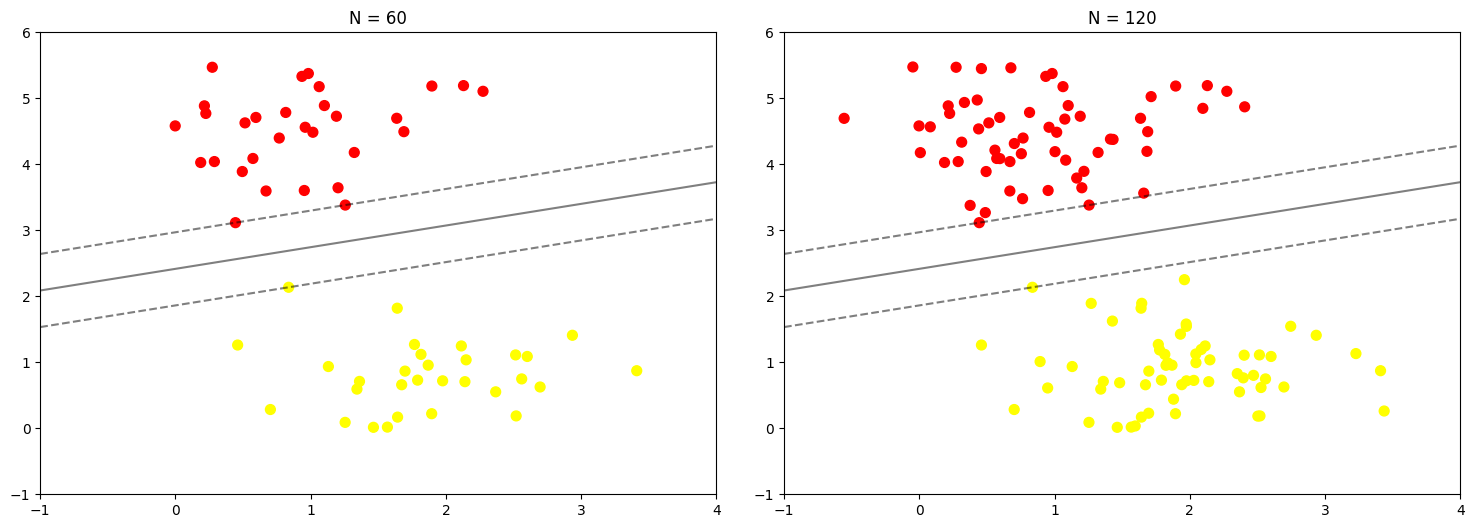

In [ ]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

Berdasarkan hasil di atas, perubahan jumlah data tidak mempengaruhi model yang digunakan. Ilustrasi lebih jelas dapat dilihat pada diagram di bawah ini




In [ ]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

NB: Kode mungkin tidak dapat dijalankan pada Google Colab. Lakukan instalasi modul ipywidgets  terlebih dahulu,




In [ ]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 31.6 MB/s  0:00:00


## **Praktikum 2** ##

Klasifikasi SVM dengan Data Dummy Non-Linier

**Pengantar**

Pada praktikum ke-2 ini, kita akan mencoba memanfaatkan SVM untuk mengklasifiaksikan data dengan distribusi non-linier. Dengan menggunakan kernel trick, SVM juga mampu membuat decision boundaries pada data non-linier.



**Langkah 1 - Ilustrasi Data Non-Linier**

Data yang terpisah secara tidak linier menjadi masalah pada model SVM. Oleh karena itu, kernel menjadi sebuah kebutuhan bagi SVM untuk melakukan fitting pada hubungan non-linier dengan sebuah classifier linier.

**Langkah 1a - Import Library**

In [ ]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

**Langkah 1b - Buat Kembali Fungsi Plotting**

In [ ]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

**Langkah 1c - Buat Data Dummy Non-Linier**

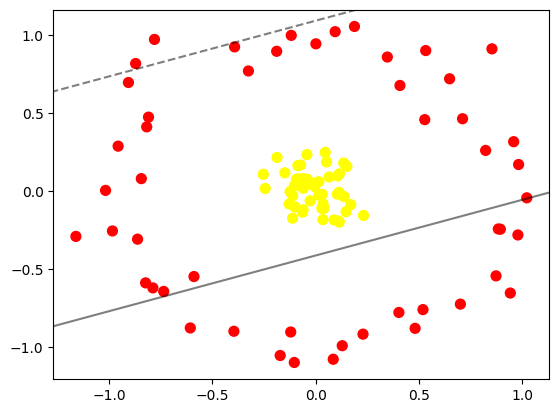

In [ ]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);



Berdasarkan contoh data di atas, tidak ditemukan sebuah garis pemisah linier yang mampu berperan sebagai pemisah data. Oleh karena itu, proyeksi (sudut pandang) lain terhadap data diperlukan supaya data dapat terpisahkan dengan jelas. Pada kegiatan ini, proyeksi yang digunakan adalah proyeksi berbasis radial.

image.png

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 0.1245763 ,  0.19891279],
       [ 0.26786762,  0.88308802],
       [-0.0814024 , -1.09689829],
       [ 0.10786293, -0.04667072],
       [ 0.29267175,  0.72935799],
       [-0.16173964,  0.90400829],
       [ 0.50071555,  0.68161743],
       [-0.12785708, -0.12480109],
       [ 0.03215764, -0.17721279],
       [-0.99046474,  0.48963578],
       [ 0.47695621,  1.00556166],
       [ 0.12005685,  0.05074289],
       [ 0.04015233,  0.11864906],
       [ 0.13092716,  0.17043044],
       [ 0.28303951, -0.93310723],
       [ 0.09499667, -0.94998125],
       [ 0.1095163 ,  0.18041649],
       [-0.04937804, -0.10251578],
       [ 0.0571482 ,  0.07621474],
       [ 0.89821642,  0.54679764],
       [ 0.0080911 , -0.00632534],
       [ 0.21969662, -1.00369797],
       [ 0.70554008, -0.86359805],
       [-0.10330658,  0.10968418],
       [ 0.11326238, -0.13337773],
       [ 0.13357084,  0.04760457],
       [ 0.8502754 , -0.56465495],
       [ 0.06959597,  0.07159825],
       [ 0.00714652,  0.84477571],
       [-0.02234426, -0.01739932],
       [-0.82121532, -0.42474684],
       [-0.06670665,  0.00913621],
       [-0.17468444,  0.26235688],
       [-0.82874289,  0.09039308],
       [-0.68443739, -0.75302998],
       [-1.03966003, -0.10902756],
       [ 0.12636781, -0.10524512],
       [-0.26108635, -0.07324852],
       [-0.59284107, -0.90473724],
       [ 0.02274747, -0.00883093],
       [-0.75274402,  0.74010723],
       [-0.08973594,  0.15246471],
       [-0.7674401 ,  0.54765342],
       [ 0.08935991,  0.16476481],
       [-0.21264188, -0.06779349],
       [ 0.06739781,  0.09614028],
       [ 0.15459568,  0.15138471],
       [-0.95400775, -0.25774721],
       [-0.15299564, -0.09490066],
       [ 0.12160564, -1.0116724 ],
       [ 0.31128906, -0.09761703],
       [-0.05245653,  0.05045317],
       [-1.04762084,  0.07435645],
       [ 0.07663345, -0.12674257],
       [ 0.96881703, -0.5299813 ],
       [-0.18854047,  0.07440258],
       [-0.11410249,  0.1257651 ],
       [-0.1305618 , -0.15141369],
       [-0.01993976, -0.05441974],
       [ 0.00558602,  0.04667623],
       [ 0.74479535,  0.46666262],
       [-0.14483487,  0.01796346],
       [-0.8279388 , -0.11153359],
       [ 0.1419318 ,  0.18752053],
       [ 0.97987252,  0.1709343 ],
       [-0.45461246, -0.73179853],
       [ 0.68900883,  0.56371804],
       [-0.51884891,  0.85658204],
       [-0.0908177 ,  0.07380154],
       [ 0.14628094, -0.09163756],
       [ 1.03922771,  0.03309699],
       [ 0.56856888,  0.76179475],
       [-0.66335652, -0.4348495 ],
       [-0.87413911, -0.22220645],
       [-0.48583702, -0.79862161],
       [ 0.98244957,  0.44762332],
       [ 1.05086427, -0.35679646],
       [-0.12164157,  0.82624678],
       [-0.64449717,  0.99613093],
       [ 0.21789997, -1.06448175],
       [-0.04673324,  1.02796369],
       [ 1.12547208,  0.46771631],
       [-0.02335365, -0.02734093],
       [ 0.62407375, -0.58644757],
       [-0.07783476,  0.07244414],
       [ 0.00486858, -0.0334824 ],
       [-0.8860453 ,  0.37949914],
       [-0.03760016, -0.14076127],
       [ 1.02302492, -0.15684954],
       [-0.36769975, -0.86669976],
       [ 0.20842306, -0.1283135 ],
       [ 0.17592586, -0.12182796],
       [-0.28558898,  0.05262465],
       [-0.11375531, -0.03173804],
       [ 0.18761955,  0.16916058],
       [ 0.12595677,  0.04714385],
       [-0.07315393,  0.06769433],
       [ 0.80615942, -0.22048237],
       [-0.3857756 ,  0.93491696],
       [ 0.3865876 , -0.76603578]]), y=array([1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0]))>

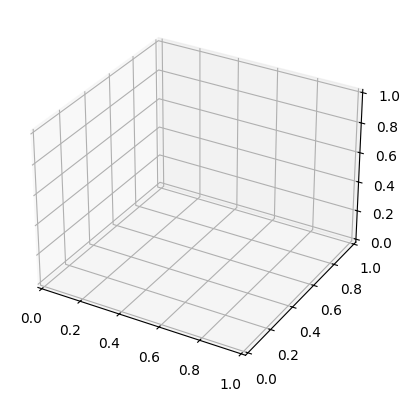

In [ ]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

	interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
	         X=fixed(X), y=fixed(y))

**Langkah 2 - Fitting Model**

Walaupun data dapat ditampilkan secara terpisah. Proyeksi titik data sejumlah N ke dalan suatu dimensi N menyebabkan beban komputasi juga bertambah. Untuk mengatasi hal ini, kernel radial basis function (RBF) pada Scikit-Learn digunakan.

In [ ]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries dari kernel RBF




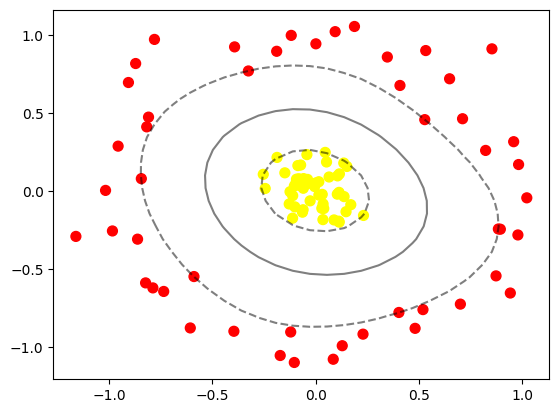

In [ ]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')

## **Praktikum 3** ##

**Pengantar**

Pada dua praktikum sebelumnya, kita sudah dapat mengatasi untuk sebaran data linier dan non-linier. Akan tetapi, jika diperhatikan, decision boundaries dapat memisahkan data secara jelas dikarenakan tidak terdapat data yang tumpang tindih (overlapping). Lalu, apa yang dapat kita lakukan ketika berhadapan dengan data yang tumpang tindih? Dalam pembuatan model pembelajaran mesin, kita mengenal istilah hyperparameter tunning. Dengan cara ini, kita dapat menyesuaikan parameter-parameter dalam model sehingga dapat mengatasi permasalahan data tumpang tindih.



**Langkah 1 - Import Library dan Buat Fungsi Plotting**

In [ ]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [ ]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

**Langkah 2 - Buat Data Dummy**

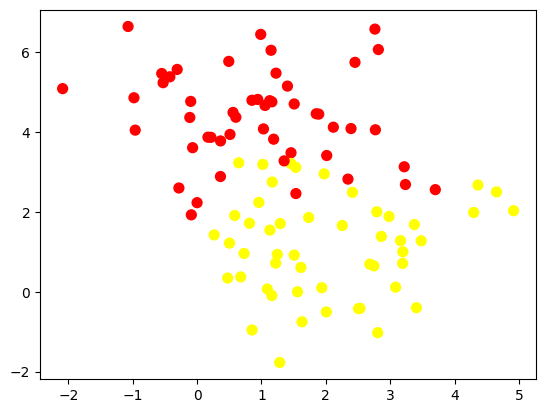

In [ ]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

**Langkah 3 - Analisis Dampak Tunning**

Untuk mengatasi hal ini, teknik penghalusan margin pada SVM dapat diterapkan. Teknik ini berfungsi untuk memasukkan beberapa titik data ke dalam margin supaya menghasilkan fitting yang lebih baik. Penebalan margin dari hasil teknik penghalusan dikelola oleh sebuah parameter tuning (dikenal sebagai C). Contoh dibawah menunjukkan perubahan pada C berdampak pada hasil fitting final.

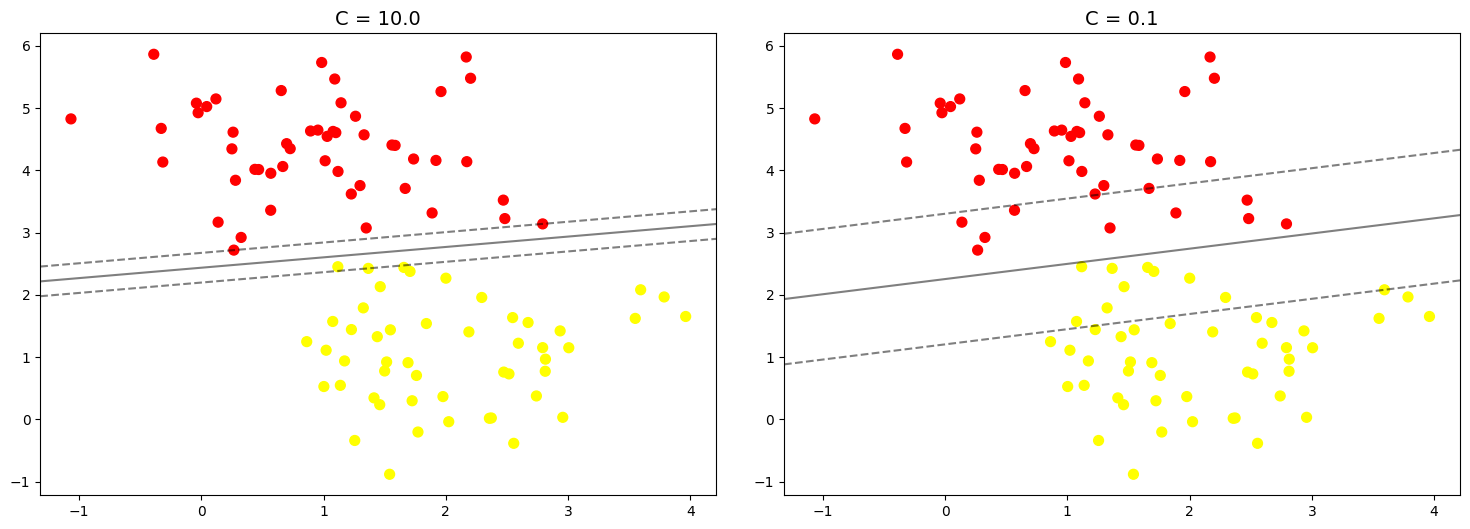

In [ ]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)

Perlu diperhatikan bahwa nilai optimal sebuah C bergantung pada setiap dataset (melalui cross-validation atau prosedur serupa).



## **Praktikum 4** ##

Klasifikasi Citra Wajah

**Pengantar**

Setelah kita memahami proses klasifikasi dengan menggunakan SVM, selanjutnya kita akan belajar melakukan klasifikasi dengan data riil berupa citra wajah. Dataset yang akan digunakan adalah dataset wajah-wajah dari ribuan publik figur.

NB: Anda mungkin memerlukan waktu yang cukup lama untuk mengunduh dataset.

**Langkah 0 - Unduh Dataset**

Dataset yang digunakan dapat diunduh secara langsung melalui scikit-learn.




In [ ]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


**Langkah 1 - Inspeksi Citra Wajah**

Lakukan inspeksi citra wajah yang akan digunakan.

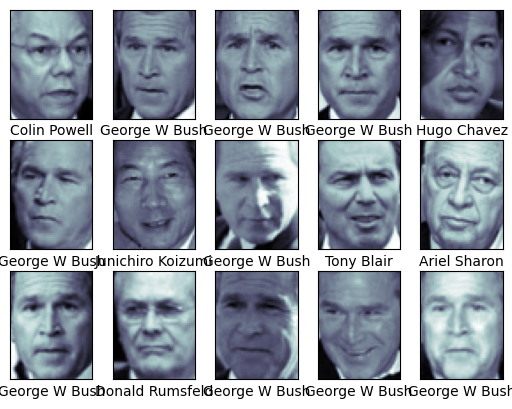

In [ ]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

**Langkah 2 - Pra Pengolahan Data**

Pada tahap ini, kita akan mencoba melakukan proses pra pengolahan data sederhana dengan menggunakan Principal Component Analysis (PCA). PCA akan memproyeksikan fitur dengan rosolusi tinggi (banyak dimensi) ke dalam principal component atau fitur yang dianggap penting saja. Metode PCA sering juga disebut sebagai metode reduksi dimensi.

In [ ]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

**Langkah 3 - Split Data**

In [ ]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

**Langkah 4 - Pembuatan Model + Tunning**

Pada langkah ini, kita akan mensimulasikan pembuatan model dan hyperparameter tunning secara langsung untuk mendapatkan nilai hyperparameter yang terbaik. Nilai tersebut dapat dicapai salah satunya dengan menggunakan teknik GridSearch. GridSearch akan mencoba menjadi kombinasi hyperparameter terbaik dengan cara melakukan pengujian performansinya satu per satu. Cara ini mudah akan tetapi memakan waktu yang lama dan komputasi yang cukup tinggi.

In [ ]:
	from sklearn.model_selection import GridSearchCV
	param_grid = {'svc__C': [1, 5, 10, 50],
	              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
	grid = GridSearchCV(model, param_grid)

	%time grid.fit(Xtrain, ytrain)
	print(grid.best_params_)
	print(grid.best_score_)

CPU times: user 1min 50s, sys: 128 ms, total: 1min 50s
Wall time: 1min 9s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Sehingga didapatkan informasi bahwa, hyperparameter terbaik dari model SVM yang kita buat adalah dengan, C=5 dan Gamma=0.001 dengan tingkat akurasi 82.88%.

Gunakan model terbaik tersebut untuk proses prediksi.




In [ ]:
	model = grid.best_estimator_
	yfit = model.predict(Xtest)

**Langkah 5 - Cek Hasil Prediksi**

Cek hasil prediksi pada citra.




Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

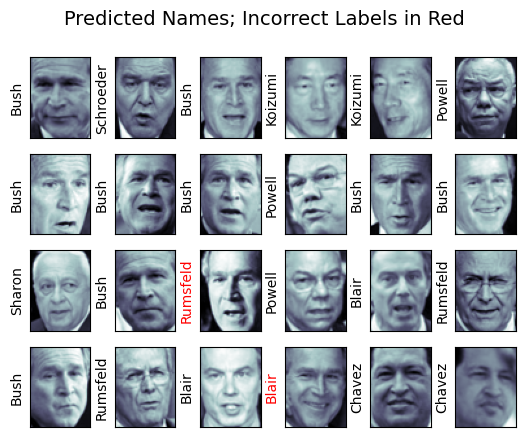

In [ ]:
	# hasil label pada data testing

	fig, ax = plt.subplots(4, 6)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
	    axi.set(xticks=[], yticks=[])
	    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
	                   color='black' if yfit[i] == ytest[i] else 'red')
	fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

Contoh di atas hanya menunjukkan satu data dengan label salah. Selanjutnya, kita akan mengukur performa model dengan classification report dan confusion matrix.

**Langkah 6 - Cek Performansi**

Pertama, cek performansi dengan classification_report dari sklearn.

In [ ]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Dari tabel tersebut, kita mendapatkan informasi terkait dengan akurasi keseluruhan, presisi, recall, dan f1-score untuk setiap label.

Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak.

Text(113.92222222222219, 0.5, 'predicted label')

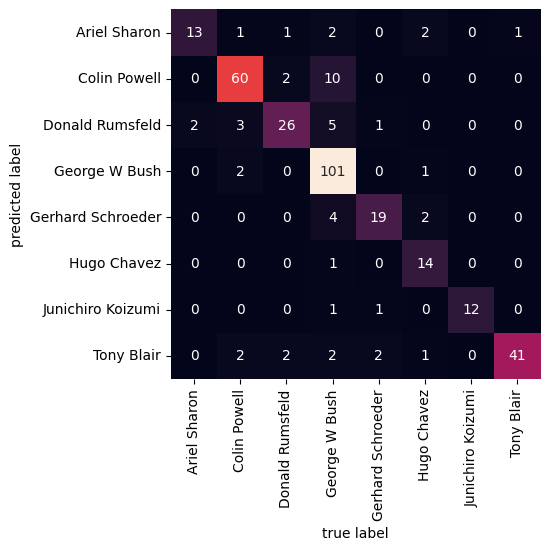

In [ ]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

## **Praktikum 5** ##

Klasifikasi Citra Siang dan Malam

**Pengantar**

Pada percobaan ini kita akan mencoba melakukan klasifikasi pada dua label citra, yaitu siang dan malam. Percobaan ini akan memberikan pengalaman bagi Anda untuk melakukan proses pra pengolahan data, ekstraksi fitur, dan melakukan klasifikasi dengan menggunakan classifier sederhana dan SVM.

Unduh dataset berikut,

**Langkah 0 - Import Library**


In [ ]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

Lakukan ekstraksi data gambar, kemudian definisikan lokasi gambar. Pada contoh ini, folder gambar berlokasi sama dengan lokasi file python.

In [ ]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

**Langkah 1 - Load Data dan Visualisasikan**

Buatlah fungsi untuk membuat daftar seluruh path dari gambar.




In [ ]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

Load gambar training




In [ ]:
	# Load training data
	train_img = load_dataset(train_dir)

In [ ]:
!unzip -q images.zip
!rm -rf __MACOSX
!ls images
!ls images/training

replace images/test/day/20151102_122322.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: test  training
day  night


In [ ]:
   !ls images/training

day  night


Lakukan pengecekan pada salah satu data pada list. List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.




In [ ]:
	# Check the first data
	# It should be a tuple consist of arrays of image and image labels
	train_img[0]

(array([[[198, 205, 213],
         [171, 178, 186],
         [173, 180, 188],
         ...,
         [169, 180, 186],
         [169, 180, 186],
         [169, 180, 186]],
 
        [[198, 205, 213],
         [171, 178, 186],
         [173, 180, 188],
         ...,
         [170, 181, 187],
         [169, 180, 186],
         [169, 180, 186]],
 
        [[198, 205, 213],
         [171, 178, 186],
         [173, 180, 188],
         ...,
         [170, 181, 187],
         [170, 181, 187],
         [170, 181, 187]],
 
        ...,
 
        [[ 55,  46,  37],
         [ 36,  27,  18],
         [ 34,  25,  18],
         ...,
         [ 37,  35,  23],
         [ 42,  40,  28],
         [ 43,  43,  31]],
 
        [[ 59,  50,  41],
         [ 40,  31,  22],
         [ 36,  27,  20],
         ...,
         [ 36,  34,  22],
         [ 40,  38,  26],
         [ 40,  40,  28]],
 
        [[ 62,  53,  44],
         [ 43,  34,  25],
         [ 37,  28,  21],
         ...,
         [ 34,  32,  20],
  

Cek ukuran gambar secara acak




In [ ]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 16
(555, 800, 3)


Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar




In [ ]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

Lakukan visualisasi gambar secara acak




Shape	: (737, 1024, 3)
Label	: night


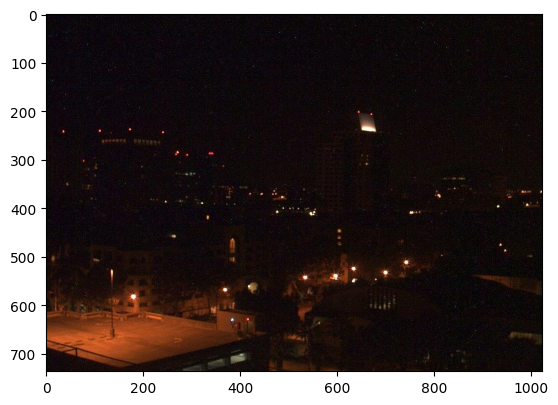

In [ ]:
random_img_viz(train_img)

**Langkah 3 - Pra Pengolahan Data**

Pada tahap ini, kita akan melakukan dua proses utama, yaitu standardisasi ukuran gambar, dan encoding label gambar.

Bualah fungsi berikut untuk menstandarkan ukuran gambar.

In [ ]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

Selanjutnya, buatlah fungsi untuk kebutuhan encoding label.




In [ ]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

Terakhir, buatlah fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list.




In [ ]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

Lakukan pra pengolahan data pada data training.




In [ ]:
train_std_img_list = preprocess(train_img)

Lakukan pengecekan ukuran gambar secara acak.




In [ ]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 147
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


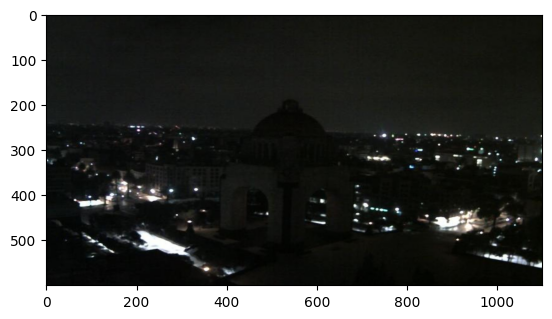

In [ ]:
random_img_viz(train_std_img_list)

Anda akan mendapatkan output seperti diatas




**WARNING!** Perhatikan ukuran (shape) dari data image. Atribut shape akan menampilkan dalam konteks baris (height) x kolom (width)

Lakukan inspeksi visual dengan fungsi random_img_viz yang telah dibuat sebelumnya pada gambar hasil pra pengolahan.

Hasilnya akan seperti gambar berikut,

**Langkah 4 - Ekstraksi Fitur**

Selanjutnya, untuk dapat membadakan antara label satu dengan label yang lain, kita memerlukan sebuah fitur. Fitur adalah penciri dari sebuah data yang dapat digunakan untuk membendakan data satu dengan yang lain. Pada percobaan kali ini, kita akan menggunakan fitur yang sederhana yaitu nilai rata-rata dari tingkat kecerahan gambar (average brightness). Namun sebelum dapat melakukan hal tersebut, kita akan mengubah ruang warna (colorspace) dari RGB menjadi HSV (Hue, Saturation, Value). Hal ini dikarenakan, tingkat kecerahan (brightness) lebih mudah didapatkan dari HSV berdasarkan nilai Valuenya.

Buatlah fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan.

In [ ]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

Lakukan pengecekan pada gambar secara acak. **INGAT! Gunakan gambar yang telah melalui proses pra pengolahan data!**

Image 70
Avg Brighness: 118.6370


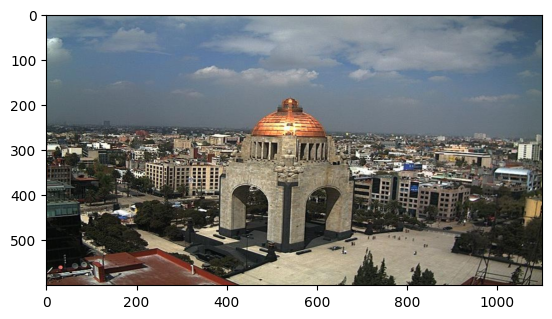

In [ ]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

**Langkah 5 - Klasifikasi dengan Metode Threshold**

Pada tahap ini, kita akan melakukan proses klasifikasi sederhana dengan menggunakan nilai ambang batas (threshold) dari nilai rata-rata kecerahan yang kita tentukan sendiri.

Buatlah fungsi berikut,

In [ ]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

Lakukan pengecekan prediksi secara acak pada data training




Image 147
Actual label: 0
Predicted label: 0


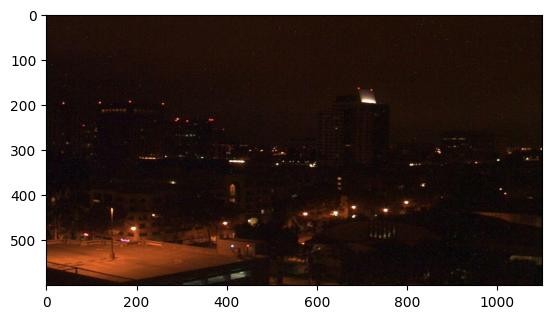

In [ ]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

**Langkah 6 - Evaluasi Manual**

Selanjutnya kita akan membuat fungsi evaluasi model sederhana, yaitu dengan membandingkan label yang diprediksi benar dengan seluruh data. Ingat kembali konsep confussion matrix.

Buatlah fungsi berikut,

In [ ]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

Lakukan evaluasi pada data training dengan nilai ambang batas 120.




In [ ]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


Anda dapat mengubah nilai ambang batas dan amati hasilnya.

Selanjutnya, kita akan melakukan evaluasi pada data testing. Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.

In [ ]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## **Klasifikasi dengan SVM** ##
Sebelumnya, kita hanya menggunakan threshold sebagai acuan. Cara ini mungkin tidak efektif dikarenakan kita harus menentukan threshold dengan tepat. Oleh karena itu, selanjutnya kita akan mencoba menggunakan model SVM untuk proses klasifikasi. Seluruh langkah yang digunakan serupa, kita hanya mengubah mulai langkah ke-4.

**Langkah 4 Alternatif - Membuat Feature Vectors.**

Perbedaan mendasar dari langkah 4 sebelumnya adalah, kita akan melakukan tabulasi semua nilai rata-rata kecerahan pada data, dan menyimpannya dalam bentuk tabel. Dalam konteks ini, kita akan membuat tabel dengan kolom fitur dan label.

Buatlah fungsi berikut,

In [ ]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

Cek hasilnya pada data training,




In [ ]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,110.086635,1.0
1,112.008461,1.0
2,102.086292,1.0
3,154.199915,1.0
4,123.617420,1.0


Maka akan tampil output seperti pada gambar



In [ ]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,109.960342,1.0
1,157.660683,1.0
2,129.345136,1.0
3,152.010606,1.0
4,131.480220,1.0


**Langkah 5 - Buat Model SVM**

Selanjutnya, kita akan membuat model SVM dengan kernel RBF (default) dengan memanfaatkan libary scikit-learn.




In [ ]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

**Langkah 6 - Evaluasi**

Selanjutnya, kita akan melakukan evaluasi pada data training dan testing dengan bantuan library scikit-learn.

In [ ]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# Tugas Praktikum - JS11 Klasifikasi 2 (SVM)

**Soal 1:** SVM pada `voice.csv` dengan kernel linier, polynomial, RBF dan split 70:30 serta 80:20.  
**Soal 2:** SVM kernel RBF untuk klasifikasi citra siang/malam dengan fitur histogram (rasio 80:20) dan hyperparameter tuning.

# SOAL 1 - SVM pada voice.csv

**1.1 Load Data**

Upload `voice.csv` ke Colab terlebih dahulu.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

voice = pd.read_csv('voice (1).csv')
print("Ukuran data:", voice.shape, "| Missing:", voice.isnull().sum().sum())
print(voice['label'].value_counts())

X = voice.drop(columns='label')
y = voice['label'].map({'male': 1, 'female': 0})

Ukuran data: (3168, 21) | Missing: 0
label
male      1584
female    1584
Name: count, dtype: int64


**1.2 Eksperimen: 2 Split x 3 Kernel**

SVM peka terhadap skala fitur, jadi data di-scale dengan `StandardScaler` di dalam `pipeline` (scaler hanya belajar dari data training sehingga tidak terjadi data leakage). Parameter lain memakai nilai default, dan `stratify=y` menjaga proporsi male/female tetap sama di train dan test.

In [ ]:
hasil = []
for test_size, nama_split in [(0.3, '70:30'), (0.2, '80:20')]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    for kernel in ['linear', 'poly', 'rbf']:
        model = make_pipeline(StandardScaler(), SVC(kernel=kernel, random_state=42))
        model.fit(X_train, y_train)
        hasil.append({
            'Split': nama_split,
            'Kernel': kernel,
            'Akurasi train': accuracy_score(y_train, model.predict(X_train)),
            'Akurasi test': accuracy_score(y_test, model.predict(X_test)),
        })

tabel = pd.DataFrame(hasil)
display(tabel.round(4))

,Split,Kernel,Akurasi train,Akurasi test
0,70:30,linear,0.9720,0.9790
1,70:30,poly,0.9666,0.9600
2,70:30,rbf,0.9838,0.9832
3,80:20,linear,0.9767,0.9748
4,80:20,poly,0.9680,0.9558
5,80:20,rbf,0.9838,0.9826


**1.3 Tabulasi Akurasi (data test)**

In [ ]:
pivot = tabel.pivot(index='Split', columns='Kernel', values='Akurasi test')[['linear', 'poly', 'rbf']]
display(pivot.round(4))

pivot.T.plot(kind='bar', figsize=(8, 5), edgecolor='k')
plt.title("Akurasi SVM pada Data Test")
plt.ylabel("Akurasi")
plt.xlabel("Kernel")
plt.ylim(0.9, 1.0)
plt.xticks(rotation=0)
plt.legend(title="Split")
plt.tight_layout()
plt.show()

**1.4 Catatan: Pengaruh Scaling (opsional)**

Sebagai bukti bahwa scaling penting pada SVM, berikut hasil tanpa scaling.

In [ ]:
tanpa = []
for test_size, nama_split in [(0.3, '70:30'), (0.2, '80:20')]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    for kernel in ['linear', 'poly', 'rbf']:
        m = SVC(kernel=kernel).fit(X_train, y_train)
        tanpa.append({'Split': nama_split, 'Kernel': kernel,
                      'Akurasi test (tanpa scaling)': accuracy_score(y_test, m.predict(X_test))})
display(pd.DataFrame(tanpa).round(4))

,Split,Kernel,Akurasi test (tanpa scaling)
0,70:30,linear,0.9201
1,70:30,poly,0.5110
2,70:30,rbf,0.6951
3,80:20,linear,0.9180
4,80:20,poly,0.5174
5,80:20,rbf,0.6940


*italicized text*## 1.5 Analisis Soal 1

| Split | Linear | Polynomial | RBF |
|---|---|---|---|
| 70:30 | 0,9790 | 0,9600 | 0,9832 |
| 80:20 | 0,9748 | 0,9558 | 0,9826 |

- **Kernel terbaik adalah RBF** pada kedua split (98,32% pada 70:30 dan 98,26% pada 80:20). Kernel RBF mampu membentuk batas keputusan non-linier yang fleksibel, cocok untuk 20 fitur suara yang hubungannya dengan jenis kelamin tidak sepenuhnya linier.
- **Kernel linier** berada di urutan kedua (97,90% dan 97,48%). Selisihnya dengan RBF kecil, artinya data suara ini sebagian besar sudah cukup terpisah secara linier.
- **Kernel polynomial** paling rendah (96,00% dan 95,58%). Akurasi training-nya juga lebih rendah dari RBF, jadi penyebabnya bukan overfitting, melainkan parameter default (derajat 3) kurang cocok untuk data ini.
- **Pengaruh split:** perbedaan antara 70:30 dan 80:20 sangat kecil (kurang dari 0,5 poin), karena data cukup besar (3.168 sampel) sehingga 70% saja sudah cukup untuk belajar. Urutan performa kernel pun sama di kedua split.
- **Scaling sangat penting:** tanpa scaling, akurasi turun drastis (polynomial sekitar 51% dan RBF sekitar 69-70%), karena fitur dengan skala besar mendominasi perhitungan jarak/kernel.

# SOAL 2 - SVM RBF pada Citra Siang dan Malam (fitur histogram)

> Bagian ini memakai variabel dari Praktikum 5 di notebook yang sama: `train_std_img_list` (hasil `preprocess(train_img)`), fungsi `load_dataset`, `preprocess`, `test_dir`. Pastikan sel-sel tersebut sudah dijalankan.

**2.1 Siapkan Data Test**

Kalau `test_std_img_list` belum dibuat di Praktikum 5, sel ini membuatnya.

In [ ]:
if 'test_std_img_list' not in globals():
    test_img = load_dataset(test_dir)
    test_std_img_list = preprocess(test_img)

print("Jumlah data train:", len(train_std_img_list))
print("Jumlah data test :", len(test_std_img_list))

Jumlah data train: 240
Jumlah data test : 160


**2.2 Ekstraksi Fitur Histogram**

Setiap gambar diubah menjadi histogram warna: 16 bin untuk masing-masing channel R, G, B (total 48 fitur), lalu dinormalisasi agar tidak bergantung pada ukuran gambar. Gambar malam akan memiliki histogram yang menumpuk di nilai piksel rendah, sedangkan gambar siang lebih tersebar ke nilai tinggi.

In [ ]:
import cv2

def extract_histogram(image, bins=16):
    fitur = []
    for ch in range(3):  # R, G, B
        hist = cv2.calcHist([image], [ch], None, [bins], [0, 256]).flatten()
        hist = hist / hist.sum()
        fitur.extend(hist)
    return np.array(fitur)

def buat_fitur(img_list, bins=16):
    X = np.array([extract_histogram(img, bins) for img, label in img_list])
    y = np.array([label for img, label in img_list])
    return X, y

# Gabungkan data train dan test, lalu split ulang dengan rasio 80:20 sesuai soal
semua_img = list(train_std_img_list) + list(test_std_img_list)
X_img, y_img = buat_fitur(semua_img)
print("Shape fitur:", X_img.shape)
print("Distribusi label:", dict(zip(*np.unique(y_img, return_counts=True))))

Shape fitur: (400, 48)
Distribusi label: {np.int64(0): np.int64(200), np.int64(1): np.int64(200)}


**2.3 Split 80:20 dan Model RBF Default**

In [162]:
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_img, y_img, test_size=0.2, random_state=42, stratify=y_img
)

base = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))
base.fit(Xi_train, yi_train)
acc_base = accuracy_score(yi_test, base.predict(Xi_test))
print("SVM RBF default (C=1, gamma='scale')")
print("Akurasi train:", round(accuracy_score(yi_train, base.predict(Xi_train)), 4))
print("Akurasi test :", round(acc_base, 4))

SVM RBF default (C=1, gamma='scale')
Akurasi train: 0.9969
Akurasi test : 1.0


**2.4 Hyperparameter Tuning (C dan gamma)**

`C` mengatur toleransi kesalahan (kecil = margin lebar, lebih halus; besar = berusaha mengklasifikasi semua titik training dengan benar), sedangkan `gamma` mengatur jangkauan pengaruh satu titik (kecil = pengaruh luas; besar = pengaruh sempit sehingga rawan overfitting). Kombinasi dipilih dengan 5-fold cross-validation **pada data training saja**, lalu akurasi test dicatat sebagai pembanding.

In [163]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1],
}
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(Xi_train, yi_train)

# Catat semua kombinasi: akurasi CV (dasar pemilihan) dan akurasi test
catatan = []
for params in grid.cv_results_['params']:
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42,
                      C=params['svc__C'], gamma=params['svc__gamma'])).fit(Xi_train, yi_train)
    catatan.append({
        'C': params['svc__C'],
        'gamma': params['svc__gamma'],
        'Akurasi train': accuracy_score(yi_train, m.predict(Xi_train)),
        'Akurasi test': accuracy_score(yi_test, m.predict(Xi_test)),
    })
catatan = pd.DataFrame(catatan)
catatan['Akurasi CV'] = grid.cv_results_['mean_test_score']
display(catatan.sort_values('Akurasi CV', ascending=False).round(4).reset_index(drop=True))

print("Parameter terbaik (berdasarkan CV):", grid.best_params_)
print("Akurasi CV terbaik                :", round(grid.best_score_, 4))

,C,gamma,Akurasi train,Akurasi test,Akurasi CV
0,100.0,0.01,1.0000,1.0000,0.9969
1,100.0,scale,1.0000,1.0000,0.9938
2,10.0,scale,1.0000,1.0000,0.9938
3,10.0,0.01,0.9969,1.0000,0.9938
4,100.0,0.001,0.9969,1.0000,0.9906
5,1.0,0.1,1.0000,1.0000,0.9875
6,10.0,0.1,1.0000,1.0000,0.9875
7,100.0,0.1,1.0000,1.0000,0.9875
8,1.0,0.001,0.9906,1.0000,0.9812
9,1.0,scale,0.9969,1.0000,0.9812


Parameter terbaik (berdasarkan CV): {'svc__C': 100, 'svc__gamma': 0.01}
Akurasi CV terbaik                : 0.9969


**2.5 Evaluasi Model Terbaik pada Data Test**

Akurasi test model default : 1.0
Akurasi test model terbaik : 1.0
              precision    recall  f1-score   support

       night       1.00      1.00      1.00        40
         day       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



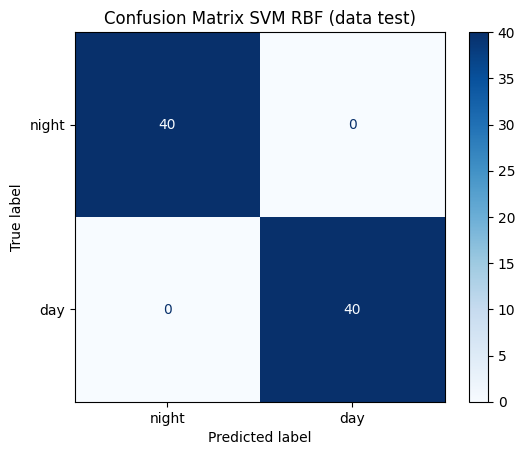

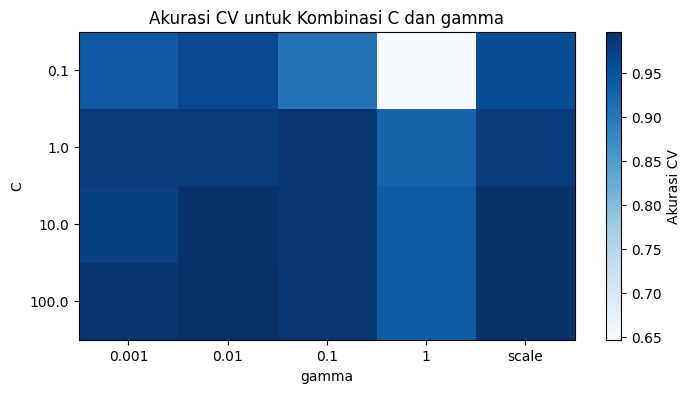

In [164]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = grid.best_estimator_
y_pred = best.predict(Xi_test)
acc_best = accuracy_score(yi_test, y_pred)

print("Akurasi test model default :", round(acc_base, 4))
print("Akurasi test model terbaik :", round(acc_best, 4))
print(classification_report(yi_test, y_pred, target_names=['night', 'day']))

ConfusionMatrixDisplay.from_predictions(yi_test, y_pred, display_labels=['night', 'day'], cmap='Blues')
plt.title("Confusion Matrix SVM RBF (data test)")
plt.show()

# Heatmap akurasi CV untuk C dan gamma
pivot_cv = catatan.pivot(index='C', columns='gamma', values='Akurasi CV')
plt.figure(figsize=(8, 4))
plt.imshow(pivot_cv.values.astype(float), cmap='Blues', aspect='auto')
plt.colorbar(label='Akurasi CV')
plt.xticks(range(len(pivot_cv.columns)), pivot_cv.columns)
plt.yticks(range(len(pivot_cv.index)), pivot_cv.index)
plt.xlabel('gamma'); plt.ylabel('C')
plt.title('Akurasi CV untuk Kombinasi C dan gamma')
plt.show()

## 2.6 Analisis Soal 2

**Data dan fitur.** Gabungan data train dan test berisi 400 gambar (200 siang dan 200 malam) yang diubah menjadi 48 fitur histogram (16 bin x 3 channel RGB). Dengan rasio 80:20, data training berisi 320 gambar dan data test 80 gambar (40 siang, 40 malam).

**Model default (C=1, gamma='scale').** Akurasi training 0,9969 dan akurasi test 1,0000.

**Hasil tuning.** Kombinasi terbaik berdasarkan cross-validation adalah **C = 100 dan gamma = 0,01** dengan akurasi CV **0,9969** (default hanya 0,9812) dan akurasi test **1,0000**. Pada confusion matrix, 40 gambar malam dan 40 gambar siang semuanya terklasifikasi benar, tanpa kesalahan. Tuning menaikkan akurasi CV dari 0,9812 menjadi 0,9969, sedangkan akurasi test sama-sama 1,0000 karena sudah mencapai nilai maksimum sejak model default.

**Pengaruh hyperparameter.**
- **Gamma terlalu besar (gamma = 1)** menyebabkan overfitting. Untuk C ≥ 1, akurasi training mencapai 1,0000, tetapi akurasi CV hanya 0,9281-0,9375 dan akurasi test turun menjadi 0,9625. Model terlalu menghafal data training.
- **Kombinasi C kecil dan gamma besar (C = 0,1; gamma = 1)** menyebabkan underfitting berat: akurasi training hanya 0,6562, akurasi test 0,6125, dan akurasi CV 0,6469.
- **C kecil dengan gamma kecil** (misalnya C = 0,1; gamma = 0,001) juga sedikit underfitting, dengan akurasi CV 0,9406 dan akurasi training 0,9562, karena model terlalu dibatasi.
- **Wilayah terbaik** ada pada C = 10-100 dengan gamma 0,001-0,1 (atau `scale`), yaitu bagian yang paling gelap pada heatmap, dengan akurasi CV di atas 0,98.

**Catatan.** Sebagian besar kombinasi sudah mencapai akurasi test 1,0000, sehingga akurasi test tidak lagi membedakan model yang baik dan lebih baik, apalagi data test hanya berisi 80 gambar. Karena itu pemilihan parameter dilakukan berdasarkan akurasi CV pada data training, yang lebih dapat diandalkan.

**Kesimpulan.** Fitur histogram warna sangat efektif untuk membedakan gambar siang dan malam, karena perbedaan keduanya terletak pada sebaran kecerahan piksel. SVM kernel RBF dengan C = 100 dan gamma = 0,01 memberi hasil terbaik dan stabil (akurasi test 100%), dengan gamma yang terlalu besar sebagai penyebab utama penurunan performa.